In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv("../datasets/sales_data.csv")

df.head()

,Order_ID,Order_Date,Product,Category,Quantity,Unit_Price,Region,Sales
0,ORD001,2025-01-05,Laptop,Electronics,2,45000.0,North,90000
1,ORD002,2025-01-12,Mouse,Electronics,5,500.0,South,2500
2,ORD003,2025-02-03,Chair,Furniture,3,3500.0,East,10500
3,ORD004,2025-02-15,Notebook,Stationery,10,50.0,West,500
4,ORD005,2025-03-08,Keyboard,Electronics,4,1200.0,North,4800


In [6]:
# Dataset dimensions
print("Shape:", df.shape)

# Column names
print("\nColumns:", df.columns.tolist())

# Dataset information
df.info()

# Statistical summary
display(df.describe())

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate records:", df.duplicated().sum())

Shape: (27, 8)

Columns: ['Order_ID', 'Order_Date', 'Product', 'Category', 'Quantity', 'Unit_Price', 'Region', 'Sales']
<class 'pandas.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Order_ID    27 non-null     str    
 1   Order_Date  27 non-null     str    
 2   Product     26 non-null     str    
 3   Category    27 non-null     str    
 4   Quantity    27 non-null     int64  
 5   Unit_Price  26 non-null     float64
 6   Region      26 non-null     str    
 7   Sales       27 non-null     int64  
dtypes: float64(1), int64(2), str(5)
memory usage: 2.8 KB


,Quantity,Unit_Price,Sales
count,27.000000,26.000000,27.000000
mean,6.629630,6896.923077,11403.703704
std,7.676879,12068.809310,18793.549046
min,1.000000,10.000000,0.000000
25%,2.000000,100.000000,1000.000000
50%,3.000000,2000.000000,4800.000000
75%,9.000000,8000.000000,14500.000000
max,30.000000,45000.000000,90000.000000



Missing values:
Order_ID      0
Order_Date    0
Product       1
Category      0
Quantity      0
Unit_Price    1
Region        1
Sales         0
dtype: int64

Duplicate records: 0


In [8]:
# Create a copy of the original dataset
df_clean = df.copy()

# Convert date column
df_clean["Order_Date"] = pd.to_datetime(df_clean["Order_Date"])

# Remove duplicate records
df_clean = df_clean.drop_duplicates()

# Handle missing values
df_clean["Region"] = df_clean["Region"].fillna("Unknown")
df_clean["Product"] = df_clean["Product"].fillna("Unknown Product")

# Replace missing prices with median
df_clean["Unit_Price"] = df_clean["Unit_Price"].fillna(
    df_clean["Unit_Price"].median()
)

# Recalculate sales
df_clean["Sales"] = df_clean["Quantity"] * df_clean["Unit_Price"]

print("Missing values after cleaning:")
print(df_clean.isnull().sum())

print("\nCleaned dataset shape:", df_clean.shape)

Missing values after cleaning:
Order_ID      0
Order_Date    0
Product       0
Category      0
Quantity      0
Unit_Price    0
Region        0
Sales         0
dtype: int64

Cleaned dataset shape: (27, 8)


In [9]:
# Total sales
print("Total Sales:", df_clean["Sales"].sum())

# Average sales
print("Average Sales:", df_clean["Sales"].mean())

# Total quantity sold
print("Total Quantity Sold:", df_clean["Quantity"].sum())

# Sales by category
category_sales = df_clean.groupby("Category")["Sales"].sum()

print("\nSales by Category:")
print(category_sales)

# Sales by region
region_sales = df_clean.groupby("Region")["Sales"].sum()

print("\nSales by Region:")
print(region_sales)

Total Sales: 313900.0
Average Sales: 11625.925925925925
Total Quantity Sold: 179

Sales by Category:
Category
Electronics    209900.0
Furniture       98500.0
Stationery       5500.0
Name: Sales, dtype: float64

Sales by Region:
Region
East        61150.0
North      162050.0
South       40300.0
Unknown     16000.0
West        34400.0
Name: Sales, dtype: float64


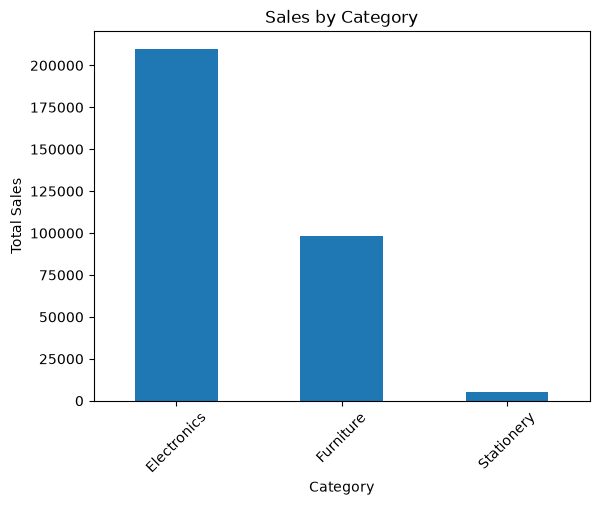

In [10]:
category_sales.plot(kind="bar")

plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

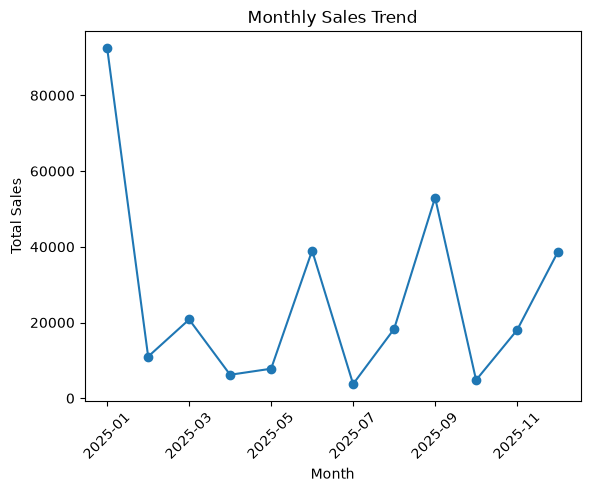

In [11]:
df_clean["Month"] = df_clean["Order_Date"].dt.to_period("M")

monthly_sales = df_clean.groupby("Month")["Sales"].sum()

monthly_sales.index = monthly_sales.index.astype(str)

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

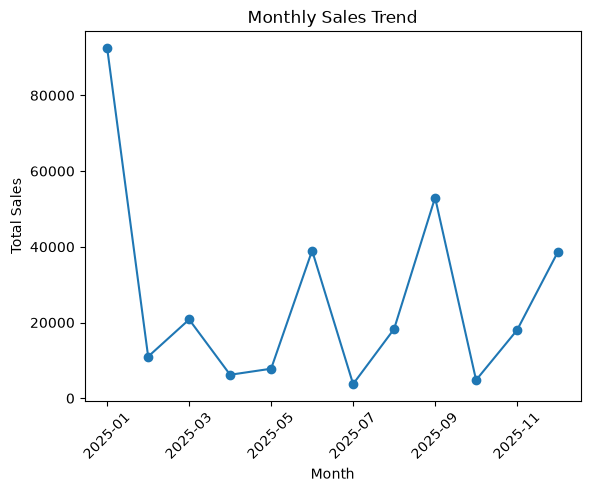

In [12]:
df_clean["Month"] = df_clean["Order_Date"].dt.to_period("M")

monthly_sales = df_clean.groupby("Month")["Sales"].sum()

monthly_sales.index = monthly_sales.index.astype(str)

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

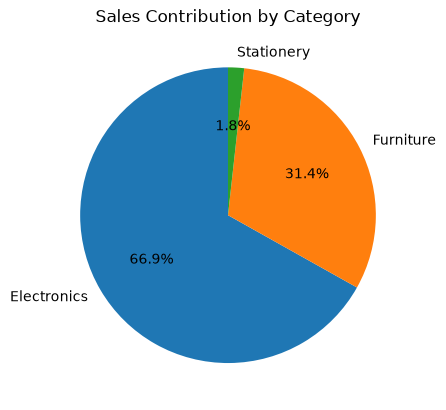

In [13]:
category_sales.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Sales Contribution by Category")
plt.ylabel("")
plt.show()

In [ ]:
# Today's exercise demonstrated how Pandas and NumPy can be used for dataset manipulation, exploration and numerical analysis. Missing values and duplicate records were handled during data cleaning. Matplotlib was used to visualize sales distribution across categories, monthly sales trends and category-wise contributions.